In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [20]:
# Read in datasets
mlb_dv_train = pd.read_csv("mlb_dv_train.csv")
mlb_dv_test = pd.read_csv("mlb_dv_test.csv")
mlb_dv_val = pd.read_csv("mlb_dv_val.csv")

In [21]:
print(mlb_dv_train.shape)
print(mlb_dv_test.shape)
print(mlb_dv_val.shape)

(8607, 119)
(2460, 119)
(1229, 119)


In [22]:
pd.set_option('display.max_columns', None)
mlb_dv_train.head(10)

,Unnamed: 0,incident_date,team,ori,game_pk,homefavor,accuracy,game_date,venue_name,venue_id,temperature,other_weather,wind,attendance,start_time,elapsed_time,game_type,status_ind,home_league_id,isTie,gameNumber,publicFacing,doubleHeader,gamedayType,tiebreaker,dayNight,scheduledInnings,reverseHomeAwayStatus,gamesInSeries,seriesGameNumber,seriesDescription,ifNecessaryDescription,teams.away.score,teams.away.leagueRecord.pct,teams.home.score,teams.home.leagueRecord.pct,status.codedGameState,status.detailedState,homewin,awaywin,umpirechangedoutcome,hometeam,dv_hour_0,dv_hour_1,dv_hour_2,dv_hour_3,dv_hour_4,dv_hour_5,dv_hour_6,dv_hour_7,dv_hour_8,dv_hour_9,dv_hour_10,dv_hour_11,dv_hour_12,dv_hour_13,dv_hour_14,dv_hour_15,dv_hour_16,dv_hour_17,dv_hour_18,dv_hour_19,dv_hour_20,dv_hour_21,dv_hour_22,dv_hour_23,dayofweek,month,year,elapsed_time_clean,end_time,game_end_time,start_time_1,game_start_time,win,lose,inaccuracy,dvcount_10pmto6am,dvcount_8pmto6am,dvcount_6pmto6am,dvcount_4pmto4am,dvcount_2pmto2am,dvcount_noontomidnight,dvcount_noonto2pm,dvcount_2pmto4pm,dvcount_4pmto6pm,dvcount_6pmto8pm,dvcount_8pmto10pm,dvcount_10pmtomidnight,dvcount_midnightto2am,dvcount_2amto4am,dvcount_4amto6am,holiday,AQI,AQI_Category,closegame,closerecords,inaccuracy_bin,yearly_avg_attendance,game_end_hour,game_start_hour,dv_hour_24,dv_hour_25,dv_hour_26,dv_hour_27,dv_hour_28,dv_hour_29,dv_hour_30,total_dv,dv_post_game,dv_pre_game,dv_in_game,favor,disfavor,favored,disfavored,disfavor_bin,top25inaccurate,top25disfavor
0,0,4/6/2009,CLE,OHCLP0000,244195,0.315522,80.303030,4/6/2009,Rangers Ballpark in Arlington,13,49,Sunny,"12 mph, Out To CF",49916,13:06:00,2:33,R,F,103,False,1,True,N,E,N,day,9,False,3,1,Regular Season,Normal Game,1,0.000,9,1.000,F,Final,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,3,1,0,0,2,1,0,0,0,Mon,4,2009,2:33,15H 39M 0S,15.650000,13H 6M 0S,13.100000,0,1,19.696970,1,2,4,5,8,8,0,4,1,0,3,0,0,1,0,0,39,Good,0,0,Above 95%,25294.51282,15,13,0,0,0,1,0,0,0,10,8,1,1,-0.315522,0.315522,0,1,75%,1,0
1,1,4/6/2009,COL,CODPD0000,244196,0.603193,87.974684,4/6/2009,Chase Field,15,80,Roof Closed,"0 mph, None",48796,12:40:00,2:58,R,F,104,False,1,True,N,E,N,day,9,False,3,1,Regular Season,Normal Game,8,0.000,9,1.000,F,Final,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Mon,4,2009,2:58,14H 98M 0S,15.633333,12H 40M 0S,12.666667,0,1,12.025316,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,41,Good,1,0,50%,32309.54321,15,12,0,0,0,0,0,0,0,1,0,1,0,-0.603193,0.603193,0,1,95%,0,1
2,2,4/6/2009,DET,MI8234900,244197,-0.124916,90.322581,4/6/2009,Rogers Centre,14,68,Roof Closed,"0 mph, None",48027,19:21:00,2:43 (:09 delay),R,F,103,False,1,True,N,E,N,night,9,False,4,1,Regular Season,Normal Game,5,0.000,12,1.000,F,Final,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,1,1,0,0,1,0,Mon,4,2009,2:43,21H 64M 0S,22.066667,19H 21M 0S,19.350000,0,1,9.677419,1,1,3,4,4,4,0,0,1,1,1,1,0,0,0,0,34,Good,0,0,25%,30626.22293,22,19,0,0,0,0,0,0,0,5,1,3,1,0.124916,-0.124916,1,0,50%,0,0
3,3,4/7/2009,COL,CODPD0000,244208,0.687492,90.410959,4/7/2009,Chase Field,15,88,Clear,"8 mph, L To R",26558,18:40:00,2:41,R,F,104,False,1,True,N,E,N,night,9,False,3,2,Regular Season,Normal Game,3,0.500,0,0.500,F,Final,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,Tue,4,2009,2:41,20H 81M 0S,21.350000,18H 40M 0S,18.666667,1,0,9.589041,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,46,Good,0,1,25%,32309.54321,21,18,0,0,0,0,0,0,0,2,1,1,0,-0.687492,0.687492,0,1,95%,0,1
4,4,4/7/2009,DET,MI8234900,244209,-0.291465,92.028986,4/7/2009,Rogers Centre,14,68,Roof Closed,"0 mph, None",16790,19:08:00,2:40,R,F,103,False,1,True,N,E,N,night,9,False,4,2,Regular Season,Normal Game,4,0.000,5,1.000,F,Final,1,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,2,0,1,1,0,1,1,1,0,0,2,1,Tue,4,2009,2:40,21H 48M 0S,21.800000,19H 8M 0S,19.133333,0,1,7.971014,5,5,7,8,9,10,2,2,1,2,1,2,1,1,0,0,33,Good,1,0,5%,30626.22293,21,19,0,1,0,1,0,0,0,13,5,7,1,0.291465,-0.291465,1,0,50%,0,0
5,5,4/7/2009,MIL,WIMPD0000,244210,0.733489,85.405405,4/7/2009,AT&T Park,2395,58,Overcast,"14 mph, Out To CF",

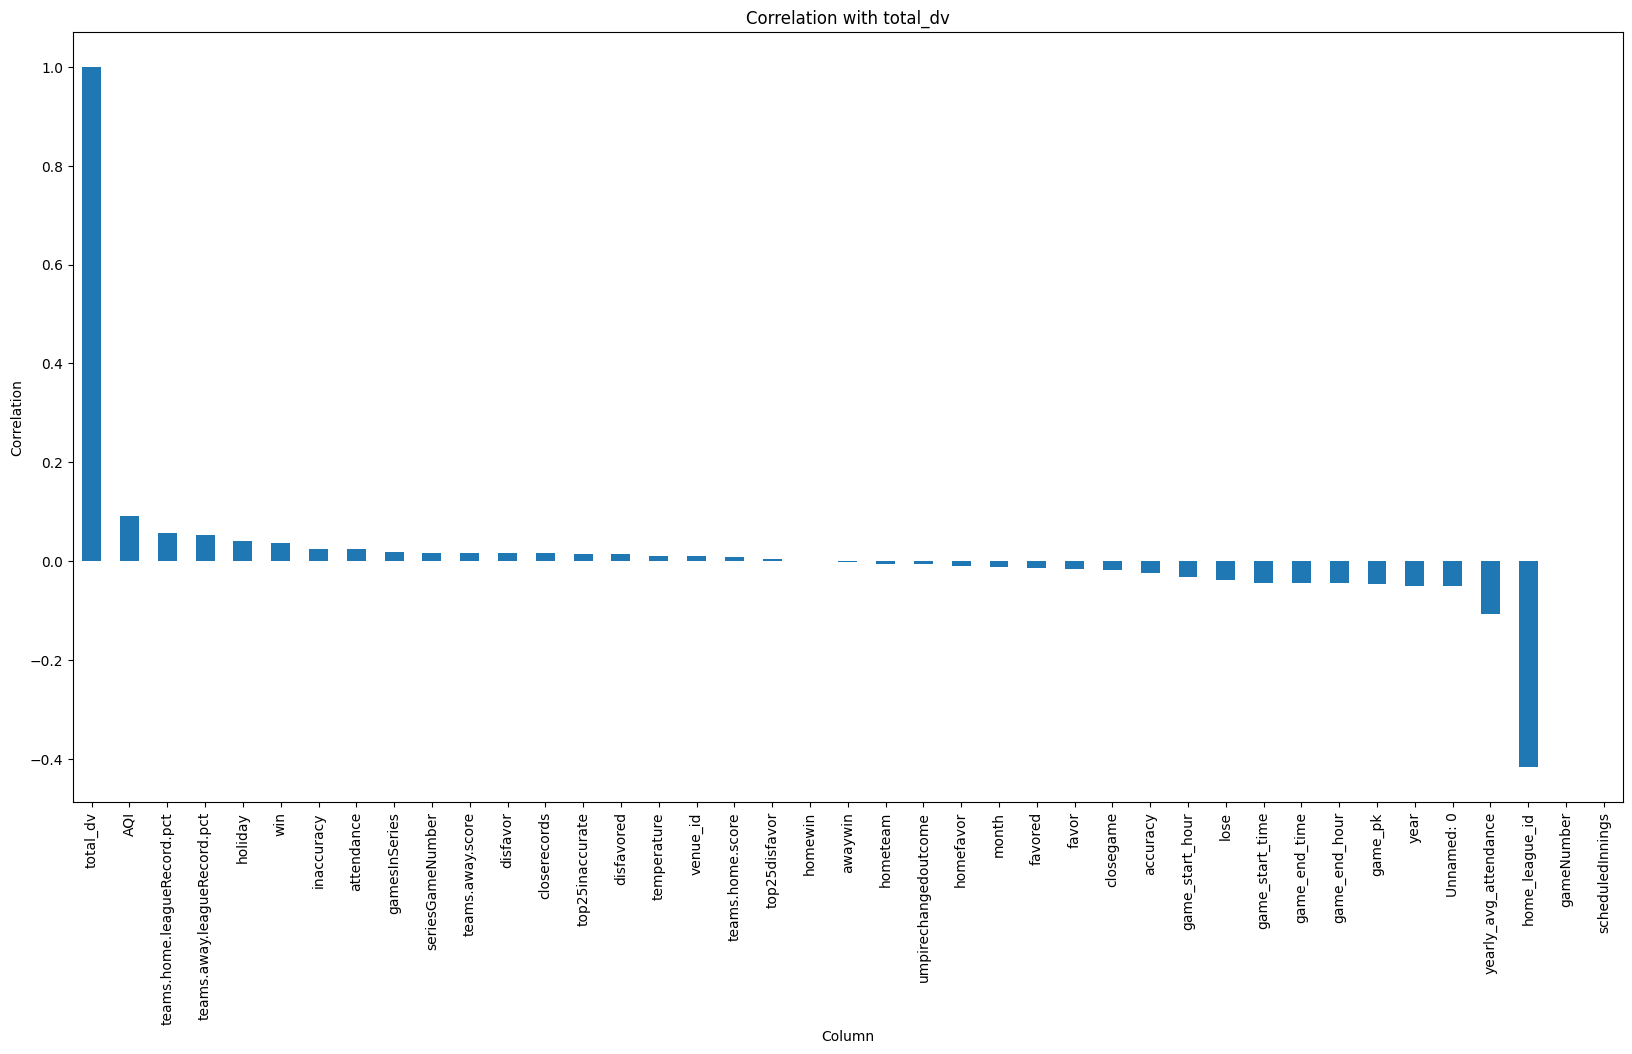

In [23]:
# Bar chart of correlations with "total_dv", only with numerical columns
total_dv_corr = mlb_dv_train[[c for c in mlb_dv_train.columns if not str(c).startswith("dv") or c == "total_dv"]].select_dtypes(include="number").corr()["total_dv"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(20, 10))
total_dv_corr.plot(kind="bar", ax=ax)
ax.set_title("Correlation with total_dv")
ax.set_xlabel("Column")
ax.set_ylabel("Correlation")
plt.show()

In [24]:
X_train = mlb_dv_train[[c for c in mlb_dv_train.columns if not str(c).startswith("dv") and not c == "total_dv"]].select_dtypes(include="number")
y_train = mlb_dv_train["total_dv"]
X_val = mlb_dv_val[[c for c in mlb_dv_val.columns if not str(c).startswith("dv") and not c == "total_dv"]].select_dtypes(include="number")
y_val = mlb_dv_val["total_dv"]
X_test = mlb_dv_test[[c for c in mlb_dv_test.columns if not str(c).startswith("dv") and not c == "total_dv"]].select_dtypes(include="number")
y_test = mlb_dv_test["total_dv"]

In [25]:
baseline_lin = LinearRegression()
baseline_lin.fit(X_train, y_train)
y_pred_lin = baseline_lin.predict(X_test)

mae_lin = mean_absolute_error(y_test, y_pred_lin)
mse_lin = mean_squared_error(y_test, y_pred_lin)
rmse_lin = np.sqrt(mse_lin)
r2_lin = r2_score(y_test, y_pred_lin)


print(f"MAE: {mae_lin}")
print(f"MSE: {mse_lin}")
print(f"RMSE: {rmse_lin}")
print(f"R2: {r2_lin}")

MAE: 4.077122152955649
MSE: 26.328080262882523
RMSE: 5.131089578528377
R2: -0.25311996403817116
